# Trial structure → `trial_structure.pdf`

One rendered frame per phase of a single 2-object trial: fixation, stimulus, delay, cue,
response, feedback.

The frames come from the repo's own `data_exploration/task_visualization` renderer, driven by the sprite
state each phase puts on screen. Only these six frames are built — one per phase, taken from
the middle of it — rather than every timestep of the trial.

The renderer needs `moog` (from `moog-games`) and `pynwb`; both are in
`requirements.txt`.

In [5]:
import ast
import sys
from pathlib import Path

import numpy as np
from matplotlib import pyplot as plt
from pynwb import NWBHDF5IO

# The repository root (where paths.py lives), found from this notebook's folder.
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'paths.py').exists())
sys.path.insert(0, str(_root))
import paths

import common

common.set_style()

sys.path.append(str(paths.TASK_VISUALIZATION))
import renderer as renderer_lib
import task_state as task_state_lib

SUBJECT, SESSION, TRIAL = 'Perle', '2022-06-11', 251
FIGSIZE = (10.0, 2.3)
OUTPUT = 'trial_structure.pdf'

PHASE_TITLES = {'fixation': 'Fixation (400ms)', 'stimulus': 'Stimulus (1000ms)',
                'delay': 'Delay (1000ms)', 'cue': 'Cue (180ms)', 'response': 'Response',
                'reveal': 'Feedback (500ms)'}
GREEN = (0.0, 1.0, 0.0)

In [6]:
nwb_path = paths.behavior_nwb(SUBJECT, SESSION)
with NWBHDF5IO(nwb_path, 'r') as io:
    nwbfile = io.read()
    trials = nwbfile.trials.to_dataframe()
    display_df = nwbfile.intervals['display'].to_dataframe()

trial = trials.loc[TRIAL]
display_df = display_df[(display_df['start_time'] > trial['start_time']) &
                        (display_df['stop_time'] < trial['stop_time'])].reset_index(drop=True)
phases = display_df['task_phase'].to_numpy()
assert not trial['broke_fixation'], 'expected a completed trial'
print(f'{SUBJECT} {SESSION} trial {TRIAL}: '
      f'{len(ast.literal_eval(trial.stimulus_object_positions))} objects, '
      f'{len(display_df)} timesteps')

# The response phase is drawn at the eye position reported during feedback, so its saccade
# arrow and the feedback panel's foveal window land on the same spot.
reveal_idx = np.where(phases == 'reveal')[0]
reveal_eye = display_df.loc[int(reveal_idx[len(reveal_idx) // 2]), 'closed_loop_eye_position']

Perle 2022-06-11 trial 251: 2 objects, 192 timesteps


In [7]:
positions = ast.literal_eval(trial.stimulus_object_positions)
identities = ast.literal_eval(trial.stimulus_object_identities)
targets = [x == 'true' for x in trial.stimulus_object_target[1:-1].split(', ')]
renderer = renderer_lib.Renderer()


def render(phase):
    """The middle frame of `phase`, with that phase's sprites on screen.

    The task state is rebuilt for each phase rather than carried forward, so a phase can be
    drawn without the ones before it. `offset` shifts which frame of the phase is used: the
    response panel is taken two frames early, before the foveal window appears, so the
    reveal of the object under the fovea is unique to the feedback panel.
    """
    where = np.where(phases == phase)[0]
    offset = -2 if phase == 'response' else 0
    step = int(where[int(np.clip(len(where) // 2 + offset, 0, len(where) - 1))])

    state = task_state_lib.get_task_state(positions, identities, targets)
    eye = reveal_eye if phase == 'response' else display_df.loc[step,
                                                                'closed_loop_eye_position']
    state['fixation'][0].scale = display_df.loc[step, 'fixation_cross_scale']
    state['eye'][0].opacity = 0
    state['eye'][0].position = eye
    state['fw'][0].position = eye
    for p in state['prey']:
        p.opacity = 0

    blank = False
    if phase == 'stimulus':
        for p in state['prey']:
            p.opacity = 255
    elif phase in ('delay', 'cue', 'response'):
        blank = trial.delay_object_blanks
        if phase != 'delay':
            state['fixation'][0].opacity = 0
            state['cue'][0].opacity = 255 if phase == 'cue' else 150
    elif phase == 'reveal':
        state['fixation'][0].opacity = 0
        state['cue'][0].opacity = 150
        state['fw'][0].opacity = 255
        for p in state['prey']:
            p.opacity = 145
    return renderer(state, trial.background_indices, blank=blank), eye


def to_pixels(position, frame):
    """Sprite position -> pixel (col, row). Sprite coordinates are in [0, 1] from the
    bottom left, and the rendered image is flipped vertically."""
    height, width = frame.shape[:2]
    return position[0] * width, (1 - position[1]) * height

saved trial_structure.pdf


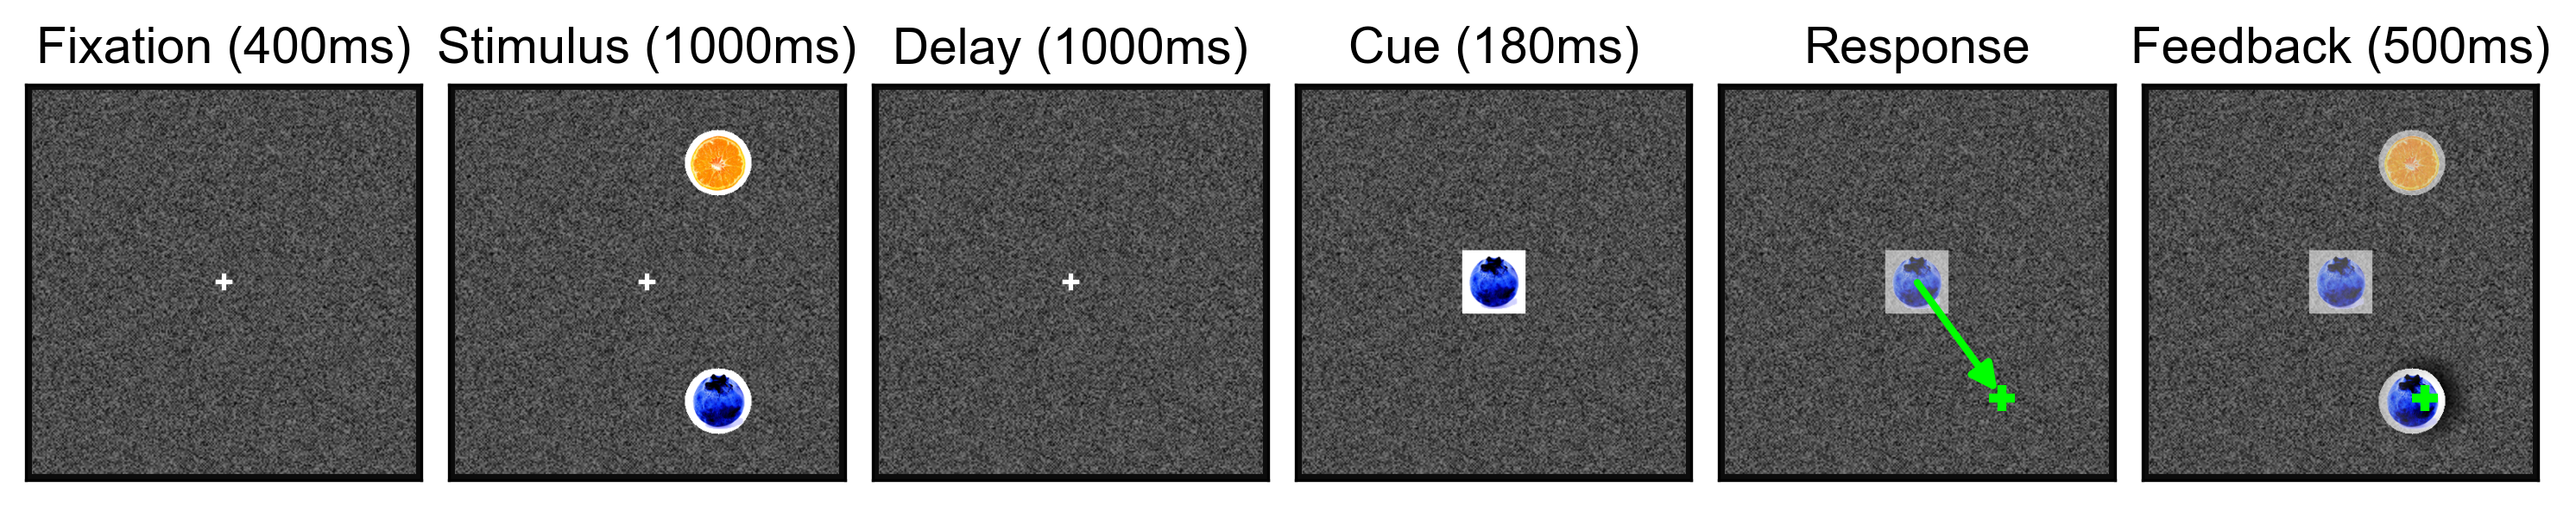

In [8]:
fig, axes = plt.subplots(1, len(PHASE_TITLES), figsize=FIGSIZE)
for ax, (phase, title) in zip(axes, PHASE_TITLES.items()):
    frame, eye = render(phase)
    ax.imshow(frame)
    eye_col, eye_row = to_pixels(eye, frame)

    if phase == 'response':
        # The saccade, from the screen centre to where the eye landed. The head stops short
        # of the green cross drawn there on the feedback panel.
        ax.annotate('', xy=(eye_col, eye_row), xytext=to_pixels((0.5, 0.5), frame),
                    arrowprops=dict(arrowstyle='-|>', color=GREEN, lw=2.0, shrinkA=0,
                                    shrinkB=2, mutation_scale=15))
    if phase in ('response', 'reveal'):
        ax.plot([eye_col], [eye_row], marker='+', color=GREEN, linestyle='none',
                markersize=7, markeredgewidth=2.5, zorder=3)

    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
fig.subplots_adjust(wspace=0.07)      # after tight_layout, which resets it
common.save(fig, OUTPUT)
plt.show()